# T-RAG · Notebook 1 — Data, prices and events (CPU only)

## About this notebook

**What it does :** This is the first step of the project. It collects the raw data and turns it into clean tables that every later notebook uses. It downloads daily stock prices for our ten companies (Tesla, Apple, Microsoft, Nvidia, Amazon, Meta, Alphabet, Netflix, AMD and Intel). The prices are adjusted for stock splits. It also downloads prices for QQQ, the Nasdaq-100 fund we use as "the market". For each stock and day it computes the abnormal return: how much the stock moved beyond what the market's move would predict. A day counts as unusual when this move is more than twice its normal size (|z| > 2).

It then builds an **events table**. The events are earnings releases and leadership changes from the companies' SEC 8-K filings, unusual price days, and the Fed's 24 interest-rate decisions. For each event it stores the stock's reaction over five trading days, from the day before to three days after (CAR[−1,+3]). Finally, it reads the FNSPID news dataset and keeps the 2021–2023 articles about our companies. It removes duplicates and auto-generated "stocks to watch" lists, and records when each article became public. Almost all articles have a date but no time, so each one is treated as public only at the end of its day. This is what later stops the system from reading an article before it existed.

**Needs :** Internet on. No GPU. About 12 minutes, mostly spent reading the large news file.

**Produces :** `trag_data/` with `prices.parquet`, `events.parquet`, `documents.parquet` (49,993 news articles), `trading_days.parquet` and `coverage.csv`.

In [1]:
# ============================ CONFIG ============================
from pathlib import Path
import os

TICKERS = ["TSLA", "AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "NFLX", "AMD", "INTC"]
MARKET = "QQQ"                      # benchmark for "the market"
START, END = "2021-01-01", "2023-12-31"
PRICE_START, PRICE_END = "2020-03-01", "2024-02-15"   # extra history for beta/sigma, extra days for CAR windows

EST_WIN, EST_GAP = 120, 10          # market-model estimation window (trading days) and gap before the day studied
VOL_WIN, Z_THRESH = 60, 2.0         # volatility window and |z| threshold for price-detected events

USE_FULLTEXT = False                # True = also stream the 23 GB nasdaq file (full article text). Adds ~1 h of CPU time.
SEC_USER_AGENT = "IITB IE624 T-RAG student project (23b3951@iitb.ac.in)"   # <-- EDIT: your team's contact

ON_KAGGLE = Path("/kaggle/working").exists()
OUT = Path("/kaggle/working/trag_data") if ON_KAGGLE else Path("trag_data")
OUT.mkdir(parents=True, exist_ok=True)
print("Output folder:", OUT.resolve())

Output folder: /kaggle/working/trag_data


In [2]:
!pip install -q -U yfinance huggingface_hub pyarrow

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
litellm 1.109.1 requires huggingface-hub<2.0,>=0.34.0, but you have huggingface-hub 2.4.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [3]:
import re, json, time, shutil, glob, warnings
import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160, "display.max_columns", 30)
print("pandas", pd.__version__, "| yfinance", yf.__version__)

pandas 2.3.3 | yfinance 1.8.0


## Step 1 — Prices

We use **split-adjusted** closes (`auto_adjust=True`). Four of our tickers split during 2021–2022, and raw prices would show fake crashes. yfinance sometimes rate-limits, so the download retries, and any ticker that is still missing is fetched again on its own.

In [4]:
def _extract(df, field, tickers):
    if isinstance(df.columns, pd.MultiIndex):
        out = df[field]
    else:  # single ticker
        out = df[[field]].rename(columns={field: tickers[0]})
    return out.reindex(columns=tickers)

def download_prices(tickers, start, end, tries=4):
    close = pd.DataFrame(); volume = pd.DataFrame()
    todo = list(tickers)
    for attempt in range(tries):
        try:
            df = yf.download(todo, start=start, end=end, auto_adjust=True, progress=False, threads=False)
            c, v = _extract(df, "Close", todo), _extract(df, "Volume", todo)
            close = c if close.empty else close.combine_first(c)
            volume = v if volume.empty else volume.combine_first(v)
        except Exception as e:
            print(f"attempt {attempt+1} failed: {e}")
        todo = [t for t in tickers if t not in close.columns or close[t].notna().sum() < 200]
        if not todo:
            break
        print("still missing:", todo, "- retrying in", 15 * (attempt + 1), "s")
        time.sleep(15 * (attempt + 1))
    if todo:
        raise RuntimeError(f"Could not download {todo}. Re-run this cell in a few minutes (Yahoo rate limit).")
    close.index = pd.to_datetime(close.index).tz_localize(None).normalize()
    volume.index = close.index
    return close[tickers].sort_index(), volume[tickers].sort_index()

ALL = TICKERS + [MARKET]
close, volume = download_prices(ALL, PRICE_START, PRICE_END)
TRADING_DAYS = pd.DatetimeIndex(close[MARKET].dropna().index)
print(close.shape, "trading days:", len(TRADING_DAYS), TRADING_DAYS.min().date(), "→", TRADING_DAYS.max().date())
close.tail(3)

(997, 11) trading days: 997 2020-03-02 → 2024-02-14


Ticker,TSLA,AAPL,MSFT,NVDA,AMZN,META,GOOGL,NFLX,AMD,INTC,QQQ
Date,,,,,,,,,,,
2024-02-12,188.130005,184.991180,405.796234,72.039200,172.339996,464.451569,146.139389,55.785000,171.910004,43.575459,429.123016
2024-02-13,184.020004,182.905518,397.059937,71.919556,168.639999,455.754913,143.771896,55.452000,171.539993,42.714439,422.429932
2024-02-14,188.710007,182.025818,400.897644,73.686432,170.979996,468.790070,144.564392,57.932999,178.699997,43.733807,427.033264


In [5]:
# Sanity check: split-adjusted prices should never show a one-day move of -50% or worse.
rets_check = close.pct_change(fill_method=None)
worst = rets_check.min().sort_values()
print("Worst single-day return per ticker (should be > -0.5):\n", worst.round(3).to_string())
assert (worst > -0.5).all(), "A one-day drop of 50%+ suggests UNADJUSTED prices (a stock split). Check auto_adjust."
print("\nTSLA around its Aug-2022 3-for-1 split (should look smooth):")
print(close.loc["2022-08-22":"2022-08-30", "TSLA"].round(2).to_string())

Worst single-day return per ticker (should be > -0.5):
 Ticker
NFLX    -0.351
META    -0.264
TSLA    -0.211
NVDA    -0.185
INTC    -0.180
MSFT    -0.147
AMD     -0.146
AMZN    -0.140
AAPL    -0.129
QQQ     -0.120
GOOGL   -0.116

TSLA around its Aug-2022 3-for-1 split (should look smooth):
Date
2022-08-22    289.91
2022-08-23    296.45
2022-08-24    297.10
2022-08-25    296.07
2022-08-26    288.09
2022-08-29    284.82
2022-08-30    277.70


## Step 2 — Returns, abnormal returns, volatility, z-scores

* `ret` = daily return; `ar_simple` = stock return − QQQ return.
* **Market model:** α and β are estimated on the **past** 120 trading days, ending 10 days before the day studied: `ar = ret − (α + β·ret_QQQ)`.
* `sigma` = standard deviation of `ar` over the previous 60 days (**shifted by one day**, so a day never judges itself). `z = ar / sigma`.

Everything uses past data only, so there is no look-ahead.

In [6]:
def market_model(r_s, r_m, est_win=EST_WIN, gap=EST_GAP, vol_win=VOL_WIN):
    minp = int(est_win * 0.8)
    cov = r_s.rolling(est_win, min_periods=minp).cov(r_m)
    var = r_m.rolling(est_win, min_periods=minp).var()
    beta_raw = cov / var
    alpha_raw = r_s.rolling(est_win, min_periods=minp).mean() - beta_raw * r_m.rolling(est_win, min_periods=minp).mean()
    beta, alpha = beta_raw.shift(gap + 1), alpha_raw.shift(gap + 1)      # window ends gap+1 days before t
    ar = r_s - (alpha + beta * r_m)
    sigma = ar.rolling(vol_win, min_periods=int(vol_win * 0.66)).std().shift(1)
    return alpha, beta, ar, sigma, ar / sigma

def build_price_table(close, volume):
    rets = close.pct_change(fill_method=None)
    r_m = rets[MARKET]
    rows = []
    for t in TICKERS:
        alpha, beta, ar, sigma, z = market_model(rets[t], r_m)
        rows.append(pd.DataFrame({
            "date": close.index, "ticker": t, "close": close[t].values, "volume": volume[t].values,
            "ret": rets[t].values, "ret_mkt": r_m.values, "alpha": alpha.values, "beta": beta.values,
            "ar": ar.values, "ar_simple": (rets[t] - r_m).values, "sigma": sigma.values, "z": z.values}))
    mk = pd.DataFrame({"date": close.index, "ticker": MARKET, "close": close[MARKET].values,
                       "volume": volume[MARKET].values, "ret": r_m.values, "ret_mkt": r_m.values})
    return pd.concat(rows + [mk], ignore_index=True)

prices = build_price_table(close, volume)
in_window = prices[(prices.date >= START) & (prices.date <= END) & (prices.ticker != MARKET)]
print("Average beta 2021–2023 (TSLA/NVDA/AMD should be the highest):")
print(in_window.groupby("ticker").beta.mean().sort_values(ascending=False).round(2).to_string())
print("\nMissing z-scores inside 2021–2023:", int(in_window.z.isna().sum()), "(should be 0 or tiny)")

Average beta 2021–2023 (TSLA/NVDA/AMD should be the highest):
ticker
NVDA     1.81
TSLA     1.66
AMD      1.60
META     1.35
AMZN     1.20
NFLX     1.15
GOOGL    1.05
AAPL     1.04
MSFT     1.02
INTC     0.93

Missing z-scores inside 2021–2023: 0 (should be 0 or tiny)


## Step 3 — Events

Three kinds of event:
1. **Price-detected:** days with |z| > 2.
2. **SEC 8-K filings**, fetched from the free EDGAR API (one request per company plus older pages). **Item 2.02** is an earnings release and **Item 5.02** is a leadership change. All ten companies release earnings **after the 4 pm close**, so day 0 is normally the next trading day. Below we use the filing's acceptance time and then **check that rule against the data**.
3. **FOMC** interest-rate decisions. They are announced at 2 pm New York time, so day 0 is the same day. They are market-wide, so they are stored with `ticker = "ALL"`.

For each event we store AR and z on day 0, and **CAR[-1,+3]**.

In [7]:
TD = TRADING_DAYS.values.astype("datetime64[ns]")

def next_trading_day(dates, same_day_ok=True):
    # First trading day >= date (same_day_ok) or > date. Works on scalars or arrays.
    d = pd.to_datetime(pd.Series(dates)).dt.normalize().values.astype("datetime64[ns]")
    idx = np.searchsorted(TD, d, side="left" if same_day_ok else "right")
    out = np.full(len(d), np.datetime64("NaT", "ns"), dtype="datetime64[ns]")
    ok = idx < len(TD)
    out[ok] = TD[idx[ok]]
    return pd.DatetimeIndex(out)

# --- FOMC decision days (statement day = second day of each meeting). Verify against federalreserve.gov if you change years.
FOMC_DATES = pd.to_datetime([
    "2021-01-27","2021-03-17","2021-04-28","2021-06-16","2021-07-28","2021-09-22","2021-11-03","2021-12-15",
    "2022-01-26","2022-03-16","2022-05-04","2022-06-15","2022-07-27","2022-09-21","2022-11-02","2022-12-14",
    "2023-02-01","2023-03-22","2023-05-03","2023-06-14","2023-07-26","2023-09-20","2023-11-01","2023-12-13"])
assert set(FOMC_DATES).issubset(set(TRADING_DAYS)), "An FOMC date is not a trading day — check the list."

In [8]:
CIK = {"TSLA": 1318605, "AAPL": 320193, "MSFT": 789019, "NVDA": 1045810, "AMZN": 1018724,
       "META": 1326801, "GOOGL": 1652044, "NFLX": 1065280, "AMD": 2488, "INTC": 50863}
ITEM_TYPES = {"2.02": "earnings", "5.02": "leadership"}

def sec_get(url):
    r = requests.get(url, headers={"User-Agent": SEC_USER_AGENT, "Accept-Encoding": "gzip, deflate"}, timeout=30)
    r.raise_for_status()
    time.sleep(0.25)                      # stay far below the SEC's 10 requests/second limit
    return r.json()

def sec_8k_events(ticker):
    j = sec_get(f"https://data.sec.gov/submissions/CIK{CIK[ticker]:010d}.json")
    frames = [pd.DataFrame(j["filings"]["recent"])]
    for f in j["filings"].get("files", []):          # older filings live in extra pages
        if f.get("filingTo", "9999") >= "2020-12-01":
            frames.append(pd.DataFrame(sec_get("https://data.sec.gov/submissions/" + f["name"])))
    df = pd.concat(frames, ignore_index=True)
    df = df[(df["form"] == "8-K") & (df["filingDate"] >= START) & (df["filingDate"] <= END)].copy()
    rows = []
    for _, r in df.iterrows():
        items = [s.strip() for s in str(r.get("items", "")).split(",")]
        for code_, etype in ITEM_TYPES.items():
            if code_ in items:
                rows.append({"ticker": ticker, "event_type": etype, "source": f"8-K item {code_}",
                             "event_date": r["filingDate"], "accepted": r.get("acceptanceDateTime"),
                             "accession": r.get("accessionNumber")})
    return pd.DataFrame(rows)

sec_frames = []
if "your_name" in SEC_USER_AGENT:
    print("⚠️  Edit SEC_USER_AGENT in the config cell first. Skipping SEC events for now.")
else:
    for t in TICKERS:
        try:
            e = sec_8k_events(t); sec_frames.append(e)
            print(f"{t}: {len(e)} events ({(e.event_type=='earnings').sum() if len(e) else 0} earnings)")
        except Exception as ex:
            print(f"{t}: SEC request failed → {ex}")
sec_events = pd.concat(sec_frames, ignore_index=True) if sec_frames else pd.DataFrame(
    columns=["ticker","event_type","source","event_date","accepted","accession"])
sec_events.head()

TSLA: 28 events (24 earnings)
AAPL: 16 events (12 earnings)
MSFT: 13 events (12 earnings)
NVDA: 18 events (13 earnings)
AMZN: 19 events (12 earnings)
META: 22 events (12 earnings)
GOOGL: 22 events (13 earnings)
NFLX: 23 events (12 earnings)
AMD: 24 events (13 earnings)
INTC: 30 events (13 earnings)


,ticker,event_type,source,event_date,accepted,accession
0,TSLA,earnings,8-K item 2.02,2023-10-18,2023-10-18T20:15:00.000Z,0001628280-23-034588
1,TSLA,earnings,8-K item 2.02,2023-10-02,2023-10-02T13:05:38.000Z,0000950170-23-050938
2,TSLA,leadership,8-K item 5.02,2023-08-07,2023-08-07T13:02:20.000Z,0000950170-23-038779
3,TSLA,earnings,8-K item 2.02,2023-07-19,2023-07-19T20:46:20.000Z,0000950170-23-033544
4,TSLA,earnings,8-K item 2.02,2023-07-03,2023-07-03T10:05:58.000Z,0000950170-23-031241


In [9]:
def sec_day0(row):
    # Use the acceptance clock time: before 16:00 -> same trading day, otherwise the next one.
    # (EDGAR acceptance times are New York clock time even though the string ends in 'Z'; checked below.)
    acc = pd.to_datetime(str(row["accepted"])[:19], errors="coerce")
    d = pd.Timestamp(row["event_date"])
    if pd.isna(acc):
        return next_trading_day([d], same_day_ok=False)[0] if row["event_type"] == "earnings" else next_trading_day([d])[0]
    if acc.hour >= 16:
        return next_trading_day([acc.normalize()], same_day_ok=False)[0]
    return next_trading_day([acc.normalize()])[0]

if len(sec_events):
    sec_events["day0"] = sec_events.apply(sec_day0, axis=1)
    # Check the timing rule: earnings should move the stock most on day0, not on the day before.
    pz = prices.set_index(["ticker", "date"])["z"]
    e = sec_events[sec_events.event_type == "earnings"]
    z0 = np.array([abs(pz.get((t, d), np.nan)) for t, d in zip(e.ticker, e.day0)])
    zm1 = np.array([abs(pz.get((t, TRADING_DAYS[TRADING_DAYS.get_loc(d) - 1]), np.nan)) for t, d in zip(e.ticker, e.day0)])
    print(f"Earnings events: {len(e)} | mean |z| on day0 = {np.nanmean(z0):.2f} vs day-1 = {np.nanmean(zm1):.2f}")
    print("✅ timing looks right" if np.nanmean(z0) > np.nanmean(zm1) else
          "⚠️ day-1 moves more than day0 — the acceptance-time rule may be off; inspect sec_events")

Earnings events: 136 | mean |z| on day0 = 4.05 vs day-1 = 0.72
✅ timing looks right


In [10]:
# --- Price-detected events
pw = prices[(prices.ticker != MARKET) & (prices.date >= START) & (prices.date <= END)]
price_ev = pw.loc[pw.z.abs() > Z_THRESH, ["ticker", "date"]].rename(columns={"date": "day0"})
price_ev["event_type"] = "price_shock"; price_ev["source"] = "price |z|>2"; price_ev["event_date"] = price_ev.day0

# --- FOMC events (market-wide)
fomc_ev = pd.DataFrame({"ticker": "ALL", "day0": FOMC_DATES, "event_type": "fomc",
                        "source": "FOMC decision", "event_date": FOMC_DATES})

cols = ["ticker", "day0", "event_type", "source", "event_date"]
raw_events = pd.concat([price_ev[cols], fomc_ev[cols],
                        sec_events[cols] if len(sec_events) else None], ignore_index=True)
raw_events["day0"] = pd.to_datetime(raw_events.day0)
raw_events["event_date"] = pd.to_datetime(raw_events.event_date)

# Merge rows that share (ticker, day0): e.g. an earnings release that also caused a price shock.
events = (raw_events.sort_values("event_type")
          .groupby(["ticker", "day0"], as_index=False)
          .agg(event_types=("event_type", lambda s: "+".join(sorted(set(s)))),
               sources=("source", lambda s: "; ".join(sorted(set(s)))),
               event_date=("event_date", "min")))

# --- AR, z and CAR[-1,+3] for each (ticker, day0)
ar_wide = prices[prices.ticker != MARKET].pivot(index="date", columns="ticker", values="ar")
z_wide = prices[prices.ticker != MARKET].pivot(index="date", columns="ticker", values="z")
pos = {d: i for i, d in enumerate(ar_wide.index)}

def car(t, d0, lo=-1, hi=3):
    i = pos.get(d0)
    if i is None or i + lo < 0 or i + hi >= len(ar_wide):
        return np.nan
    return ar_wide[t].iloc[i + lo:i + hi + 1].sum(min_count=hi - lo + 1)

rows = []
for _, ev in events.iterrows():
    tick_list = TICKERS if ev.ticker == "ALL" else [ev.ticker]
    for t in tick_list:              # FOMC rows are expanded to every ticker for the impact numbers
        rows.append({"ticker_scope": ev.ticker, "ticker": t, "day0": ev.day0, "event_types": ev.event_types,
                     "sources": ev.sources, "event_date": ev.event_date,
                     "ar_day0": ar_wide[t].get(ev.day0, np.nan), "z_day0": z_wide[t].get(ev.day0, np.nan),
                     "car_m1_p3": car(t, ev.day0)})
events_full = pd.DataFrame(rows)

# Overlap flag: event window [-1,+3] contains an FOMC day (for non-FOMC events)
fomc_pos = np.array([pos[d] for d in FOMC_DATES if d in pos])
def overlaps_fomc(d0):
    i = pos.get(d0)
    return bool(i is not None and np.any((fomc_pos >= i - 1) & (fomc_pos <= i + 3)))
events_full["overlaps_fomc"] = [overlaps_fomc(d) and "fomc" not in et
                                for d, et in zip(events_full.day0, events_full.event_types)]
events_full.insert(0, "event_id", [f"ev_{i:05d}" for i in range(len(events_full))])

print("Events per type:\n", events_full.event_types.value_counts().to_string())
print("\nCompany-specific events per ticker:\n",
      events_full[events_full.ticker_scope != "ALL"].ticker.value_counts().to_string())
events_full.sort_values("car_m1_p3").head(5)

Events per type:
 event_types
price_shock                        269
fomc                               240
earnings+price_shock                91
leadership                          71
earnings                            39
earnings+leadership                  3
earnings+leadership+price_shock      3
leadership+price_shock               2

Company-specific events per ticker:
 ticker
AMD      62
TSLA     57
INTC     54
AAPL     51
NVDA     48
GOOGL    45
NFLX     42
META     42
AMZN     39
MSFT     38


,event_id,ticker_scope,ticker,day0,event_types,sources,event_date,ar_day0,z_day0,car_m1_p3,overlaps_fomc
587,ev_00587,NFLX,NFLX,2022-04-20,earnings+price_shock,8-K item 2.02; price |z|>2,2022-04-19,-0.328906,-13.479906,-0.340239,False
507,ev_00507,META,META,2022-02-03,earnings+price_shock,8-K item 2.02; price |z|>2,2022-02-02,-0.219059,-15.712626,-0.304163,False
584,ev_00584,NFLX,NFLX,2022-01-21,earnings+price_shock,8-K item 2.02; price |z|>2,2022-01-20,-0.197584,-14.498391,-0.285547,True
518,ev_00518,META,META,2022-10-27,earnings+price_shock,8-K item 2.02; price |z|>2,2022-10-26,-0.220418,-13.390659,-0.282545,False
517,ev_00517,META,META,2022-10-25,price_shock,price |z|>2,2022-10-25,0.031905,2.037020,-0.259076,False


## Step 4 — News (FNSPID)

FNSPID's news lives on Hugging Face in two files:
* `All_external.csv` (**5.73 GB**): mostly headlines from many publishers. **Always used.**
* `nasdaq_exteral_data.csv` (**23.2 GB**): includes article text. Read **automatically** if the first file gives fewer than 50,000 rows for our tickers in 2021–2023, or always if `USE_FULLTEXT = True`.

Both passes print diagnostics: sample dates, the most common symbols, and how many rows our tickers have in each year.

The loader (1) uses a copy already attached under `/kaggle/input` if there is one, (2) otherwise downloads to `/tmp` when there's enough disk, (3) otherwise **streams** the file over the internet. The file is read in chunks, and only our tickers in 2021–2023 are kept, so RAM stays small. `FB` is mapped to `META` and `GOOG` to `GOOGL`.

In [11]:
REPO = "Zihan1004/FNSPID"
NEWS_FILES = {"external": ("Stock_news/All_external.csv", 5.73),
              "nasdaq":   ("Stock_news/nasdaq_exteral_data.csv", 23.2)}
SYMBOL_MAP = {t: t for t in TICKERS} | {"FB": "META", "GOOG": "GOOGL"}
YEARS = {str(y) for y in range(int(START[:4]), int(END[:4]) + 1)}

def resolve_source(key):
    rel, size_gb = NEWS_FILES[key]
    name = Path(rel).name
    for pat in [f"/kaggle/input/*/{name}", f"/kaggle/input/*/*/{name}", f"/kaggle/input/*/*/*/{name}"]:
        hits = glob.glob(pat)
        if hits:
            print("Using attached Kaggle copy:", hits[0]); return hits[0]
    free_gb = shutil.disk_usage("/tmp").free / 1e9
    if free_gb > size_gb * 1.15 + 3:
        from huggingface_hub import hf_hub_download
        print(f"Downloading {name} ({size_gb} GB) to /tmp (free: {free_gb:.0f} GB)…")
        return hf_hub_download(REPO, rel, repo_type="dataset", local_dir="/tmp/fnspid")
    url = f"https://huggingface.co/datasets/{REPO}/resolve/main/{rel}"
    print(f"Not enough disk ({free_gb:.0f} GB free) — streaming {name} from Hugging Face")
    return url

def norm_symbol(s):
    s = s.fillna("").str.upper().str.strip().str.replace("$", "", regex=False)
    s = s.str.split(":").str[-1]                 # "NASDAQ:TSLA" -> "TSLA"
    return s.str.split(".").str[0].str.strip()   # "TSLA.O" -> "TSLA"

def filter_news(src, key, chunksize=250_000):
    header = pd.read_csv(src, nrows=0).columns.tolist()
    find = lambda n: next((c for c in header if c.strip().lower() == n.lower()), None)
    cmap = {"date": find("Date"), "title": find("Article_title"), "symbol": find("Stock_symbol"),
            "url": find("Url"), "publisher": find("Publisher"), "text": find("Article"),
            "summary": find("Lsa_summary")}
    print("Columns found:", {k: v for k, v in cmap.items() if v})
    assert cmap["date"] and cmap["title"] and cmap["symbol"], f"Unexpected header: {header}"
    if key == "external":                       # headlines file: skip the (mostly empty) long-text columns
        cmap["text"] = cmap["summary"] = None
    usecols = [c for c in cmap.values() if c]
    inv = {v: k for k, v in cmap.items() if v}
    kept, n_read, t0 = [], 0, time.time()
    ours_by_year = pd.Series(dtype="int64")     # diagnostics: our tickers in ANY year
    reader = pd.read_csv(src, usecols=usecols, dtype=str, chunksize=chunksize,
                         on_bad_lines="skip", encoding_errors="replace")
    for i, ch in enumerate(reader):
        n_read += len(ch)
        ch = ch.rename(columns=inv)
        sym = norm_symbol(ch["symbol"])
        year = ch["date"].str.extract(r"((?:19|20)\d{2})", expand=False)
        if i == 0:
            print("  sample Date values :", ch["date"].dropna().head(3).tolist())
            print("  top symbols (chunk 1):", sym.value_counts().head(12).to_dict())
        ours = sym.isin(SYMBOL_MAP.keys())
        ours_by_year = ours_by_year.add(year[ours].value_counts(), fill_value=0)
        m = ours & year.isin(YEARS)
        if m.any():
            sub = ch[m].copy()
            sub["ticker"] = sym[m].map(SYMBOL_MAP)
            for c in ("text", "summary"):
                if c in sub:
                    sub[c] = sub[c].str.slice(0, 3000)
            kept.append(sub)
        if i % 20 == 0:
            print(f"  {key}: {n_read/1e6:6.1f}M rows read | kept {sum(map(len, kept)):,} | {time.time()-t0:5.0f}s")
    out = pd.concat(kept, ignore_index=True) if kept else pd.DataFrame(columns=list(inv.values()) + ["ticker"])
    out["source_file"] = key
    yrs = ours_by_year.sort_index().astype(int)
    print(f"✔ {key}: read {n_read:,} rows, kept {len(out):,} in {time.time()-t0:.0f}s")
    print(f"  our tickers by year in this file (all years): {yrs[yrs.index >= '2015'].to_dict()}")
    return out

MIN_ROWS = 50_000          # fewer kept rows than this -> also read the nasdaq file automatically
news_parts = [filter_news(resolve_source("external"), "external")]
if USE_FULLTEXT or len(news_parts[0]) < MIN_ROWS:
    if not USE_FULLTEXT:
        print(f"\nOnly {len(news_parts[0]):,} rows from All_external.csv → also reading nasdaq_exteral_data.csv (23 GB).")
    news_parts.append(filter_news(resolve_source("nasdaq"), "nasdaq", chunksize=100_000))
raw_news = pd.concat([p for p in news_parts if len(p)], ignore_index=True) if any(len(p) for p in news_parts) else pd.DataFrame()
if raw_news.empty:
    raise RuntimeError("No news rows matched our tickers/years in either file. Copy the 'sample Date values', "
                       "'top symbols' and 'our tickers by year' lines above and send them back.")
print(raw_news.groupby(["source_file", "ticker"]).size().unstack(0).fillna(0).astype(int).to_string())
raw_news.head(3)

Stock_news/All_external.csv: reconstructing file:   0%|          |  0.00B / 5.73GB            

Stock_news/All_external.csv: downloading bytes:           |  0.00B            

Columns found: {'date': 'Date', 'title': 'Article_title', 'symbol': 'Stock_symbol', 'url': 'Url', 'publisher': 'Publisher', 'text': 'Article', 'summary': 'Lsa_summary'}
  sample Date values : ['2020-06-05 06:30:54 UTC', '2020-06-03 06:45:20 UTC', '2020-05-26 00:30:07 UTC']
  top symbols (chunk 1): {'BABA': 2858, 'AA': 2739, 'BBRY': 2580, 'BMY': 2528, 'AGN': 2408, 'CAT': 2322, 'CHK': 2246, 'ADBE': 1999, 'AZN': 1984, 'ATVI': 1953, 'BIIB': 1907, 'BIDU': 1885}
  external:    0.2M rows read | kept 0 |     2s
  external:    5.2M rows read | kept 0 |    61s
  external:   10.2M rows read | kept 0 |    98s
✔ external: read 13,057,514 rows, kept 0 in 126s
  our tickers by year in this file (all years): {'2015': 180, '2016': 632, '2017': 1374, '2018': 1959, '2019': 5238, '2020': 4862}

Only 0 rows from All_external.csv → also reading nasdaq_exteral_data.csv (23 GB).


Stock_news/nasdaq_exteral_data.csv: reconstructing file:   0%|          |  0.00B / 23.2GB            

Stock_news/nasdaq_exteral_data.csv: downloading bytes:           |  0.00B            

Columns found: {'date': 'Date', 'title': 'Article_title', 'symbol': 'Stock_symbol', 'url': 'Url', 'publisher': 'Publisher', 'text': 'Article', 'summary': 'Lsa_summary'}
  sample Date values : ['2023-12-16 23:00:00 UTC', '2023-12-12 00:00:00 UTC', '2023-12-12 00:00:00 UTC']
  top symbols (chunk 1): {'ACGLO': 9014, 'AAPL': 8865, 'AFGD': 8399, 'AAL': 6715, 'ABBV': 5698, 'ADBE': 4444, 'ABT': 4055, 'AEO': 2869, 'ACN': 2735, 'ACB': 2632, 'ADI': 2109, 'ADM': 2052}
  nasdaq:    0.1M rows read | kept 8,865 |    10s
  nasdaq:    2.1M rows read | kept 46,321 |   186s
  nasdaq:    4.1M rows read | kept 55,033 |   247s
  nasdaq:    6.1M rows read | kept 55,033 |   297s
  nasdaq:    8.1M rows read | kept 55,033 |   314s
  nasdaq:   10.1M rows read | kept 55,033 |   331s
  nasdaq:   12.1M rows read | kept 55,033 |   348s
  nasdaq:   14.1M rows read | kept 55,033 |   365s
✔ nasdaq: read 15,549,299 rows, kept 55,033 in 400s
  our tickers by year in this file (all years): {'2015': 180, '2016': 666, '201

,date,title,symbol,url,publisher,text,summary,ticker,source_file
0,2023-12-16 22:00:00 UTC,My 6 Largest Portfolio Holdings Heading Into 2...,AAPL,https://www.nasdaq.com/articles/my-6-largest-p...,NaN,"After an absolute disaster of a year in 2022, ...",3: Apple There's little question that Apple (N...,AAPL,nasdaq
1,2023-12-16 22:00:00 UTC,Brokers Suggest Investing in Apple (AAPL): Rea...,AAPL,https://www.nasdaq.com/articles/brokers-sugges...,NaN,"When deciding whether to buy, sell, or hold a ...",Let's take a look at what these Wall Street he...,AAPL,nasdaq
2,2023-12-16 21:00:00 UTC,"Company News for Dec 19, 2023",AAPL,https://www.nasdaq.com/articles/company-news-f...,NaN,Shares of Apple Inc. AAPL lost 0.9% on China’s...,Shares of Apple Inc. AAPL lost 0.9% on China’s...,AAPL,nasdaq


## Step 5 — Clean the news and map it onto trading days

* **Timestamps** are converted from UTC to New York time.
  * Published **before 16:00** on a trading day → `day0` = that day.
  * Published later, or at a weekend or holiday → `day0` = next trading day.
* **Date-only timestamps** (`00:00:00`) are flagged `time_missing`. For safety, `available_at` is set to the **end** of that day, so retrieval can never see them early.
* **De-duplication:** same URL, or same normalised headline + ticker + date.
* **Junk filter:** auto-generated lists ("stocks that hit 52-week highs…") are dropped unless they name the company.
* `text_for_scoring` = headline (+ the first part of the summary or article, if any). This is what FinBERT and the embedder will read in Notebook 2.

In [12]:
ALIASES = {
    "TSLA": ["tesla", "tsla"], "AAPL": ["apple", "aapl", "iphone"], "MSFT": ["microsoft", "msft"],
    "NVDA": ["nvidia", "nvda"], "AMZN": ["amazon", "amzn", "aws"],
    "META": ["meta platforms", "meta", "facebook", "fb", "instagram", "whatsapp"],
    "GOOGL": ["alphabet", "google", "googl", "goog", "youtube"], "NFLX": ["netflix", "nflx"],
    "AMD": ["amd", "advanced micro devices"], "INTC": ["intel", "intc"]}
ALIAS_RE = {t: re.compile(r"\b(" + "|".join(map(re.escape, a)) + r")\b", re.I) for t, a in ALIASES.items()}
GENERIC_RE = re.compile(
    r"(?:stocks? (?:that|to watch|moving|making|hitting)|52-week|\btop \d+\b|\b\d+ (?:stocks|reasons|things)\b|"
    r"mid-?day|pre-?market (?:movers|gainers|losers)|after-?hours movers|unusual options|options activity|"
    r"biggest movers|trending tickers|market (?:wrap|update|summary)|earnings (?:scheduled|calendar)|"
    r"insider (?:buying|selling) (?:in|at)|whale)", re.I)

def clean_news(df):
    n0 = len(df)
    d = df.copy()
    d["title"] = d["title"].fillna("").str.strip()
    d = d[d.title.str.len() >= 15]
    ds = d["date"].str.replace(" UTC", "", regex=False).str.strip()
    d["published_at"] = pd.to_datetime(ds, format="%Y-%m-%d %H:%M:%S", errors="coerce", utc=True)
    bad = d.published_at.isna()
    d.loc[bad, "published_at"] = pd.to_datetime(ds[bad], errors="coerce", utc=True, format="mixed")
    d = d[d.published_at.notna()]
    d = d[(d.published_at >= pd.Timestamp(START, tz="UTC")) &
          (d.published_at < pd.Timestamp(END, tz="UTC") + pd.Timedelta(days=1))]

    # --- de-duplicate
    d["norm_title"] = d.title.str.lower().str.replace(r"[^a-z0-9 ]", " ", regex=True).str.split().str.join(" ")
    d = d.sort_values("published_at")
    if "url" in d:
        has_url = d.url.notna() & (d.url.str.len() > 10)
        d = pd.concat([d[has_url].drop_duplicates(["ticker", "url"]), d[~has_url]])
    d["pub_date"] = d.published_at.dt.date
    d = d.drop_duplicates(["ticker", "norm_title", "pub_date"]).sort_values("published_at")
    # near-duplicate across days: same headline+ticker within 3 days
    gap = d.groupby(["ticker", "norm_title"]).published_at.diff()
    d = d[~(gap.notna() & (gap < pd.Timedelta(days=3)))]

    # --- relevance / junk
    d["mentions_company"] = [bool(ALIAS_RE[t].search(s)) for t, s in zip(d.ticker, d.title)]
    d["tickers_mentioned"] = [",".join(t for t, rx in ALIAS_RE.items() if rx.search(s)) for s in d.title]
    d["is_generic"] = d.title.str.contains(GENERIC_RE)
    d = d[d.mentions_company | ~d.is_generic]

    # --- time handling: day0 and available_at
    et = d.published_at.dt.tz_convert("America/New_York")
    d["time_missing"] = (d.published_at.dt.hour == 0) & (d.published_at.dt.minute == 0) & (d.published_at.dt.second == 0)
    after_close = et.dt.hour >= 16
    cand = et.dt.tz_localize(None).dt.normalize()
    cand = cand.where(~after_close, cand + pd.Timedelta(days=1))
    utc_date = d.published_at.dt.tz_localize(None).dt.normalize()
    cand = cand.where(~d.time_missing, utc_date)              # date-only rows: use the stated calendar date
    d["day0"] = next_trading_day(cand.values).values
    end_of_day_et = (utc_date + pd.Timedelta(hours=23, minutes=59, seconds=59)).dt.tz_localize("America/New_York").dt.tz_convert("UTC")
    d["available_at"] = d.published_at.where(~d.time_missing, end_of_day_et)

    # --- text used by the models later
    summ = d["summary"].fillna("") if "summary" in d else pd.Series("", index=d.index)
    body = d["text"].fillna("") if "text" in d else pd.Series("", index=d.index)
    extra = summ.where(summ.str.len() >= 80, body)          # prefer the summary, else the article's opening
    extra = extra.fillna("").str.replace(r"\s+", " ", regex=True).str.slice(0, 600)
    d["text_for_scoring"] = (d.title + ". " + extra).str.strip(" .")
    d["has_text"] = extra.str.len() > 50
    d = d.reset_index(drop=True)
    d.insert(0, "doc_id", [f"news_{i:07d}" for i in range(len(d))])
    keep = ["doc_id", "ticker", "tickers_mentioned", "source_file", "publisher", "published_at", "available_at",
            "time_missing", "day0", "title", "text_for_scoring", "has_text", "url", "mentions_company"]
    d = d[[c for c in keep if c in d]]
    print(f"Cleaning: {n0:,} → {len(d):,} documents")
    return d

documents = clean_news(raw_news)
print("Share with missing time-of-day:", round(documents.time_missing.mean(), 3))
print("Share mentioning ≥2 of our companies:", round((documents.tickers_mentioned.str.count(",") >= 1).mean(), 3))
documents.sample(5, random_state=0)[["ticker", "published_at", "day0", "title"]]

Cleaning: 55,033 → 49,993 documents
Share with missing time-of-day: 0.997
Share mentioning ≥2 of our companies: 0.085


,ticker,published_at,day0,title
6595,GOOGL,2022-04-28 00:00:00+00:00,2022-04-28,Is Alphabet's Stock a Buy Now?
29355,NVDA,2023-05-25 00:00:00+00:00,2023-05-25,Nasdaq leads Wall Street rally after Nvidia's ...
46491,MSFT,2023-11-13 00:00:00+00:00,2023-11-13,Alphabet (GOOGL) Boosts Search Business With L...
36590,MSFT,2023-08-04 00:00:00+00:00,2023-08-04,Warren Buffett Detailed Fundamental Analysis -...
21668,MSFT,2023-02-13 00:00:00+00:00,2023-02-13,US STOCKS-Nasdaq set for higher open as megaca...


## Step 6 — Coverage, sanity checks, save

* The **coverage table** goes straight into the report's Data section. If a ticker has very few articles (say under 300 a year), drop it or set `USE_FULLTEXT = True`.


year    2021  2022  2023  2024  total  % with text  % time missing
ticker                                                            
AAPL       0  2822  5180     0   8002        100.0            99.7
AMD      754  1740  1966     5   4465        100.0            99.4
AMZN       0     0  4293     0   4293        100.0            99.5
GOOGL   1329  1670  2078     0   5077        100.0            99.8
INTC    1125  1316  1970     0   4411        100.0            99.9
MSFT       0  2431  5495     0   7926        100.0            99.7
NVDA     626  2171  5082     0   7879        100.0            99.8
TSLA       0  2905  5035     0   7940        100.0            99.8

⚠️ Thin coverage (<300 docs in some year): ['AAPL', 'AMZN', 'MSFT', 'TSLA'] → consider USE_FULLTEXT=True or dropping them.


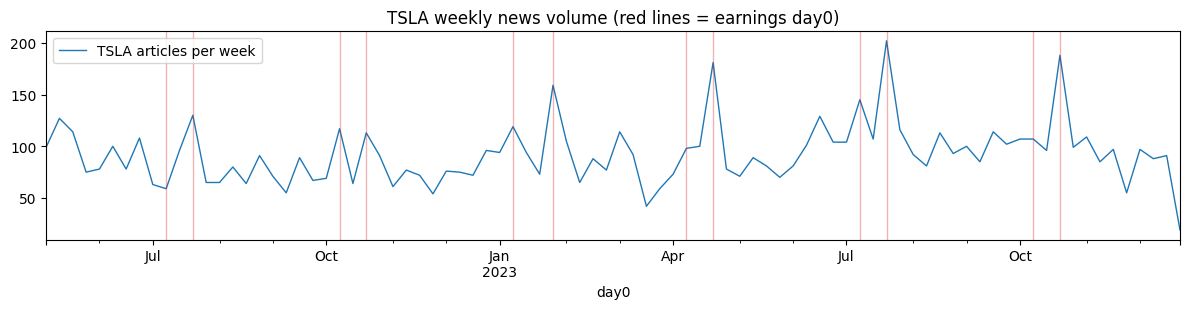

In [13]:
documents["year"] = pd.to_datetime(documents.day0).dt.year
coverage = documents.pivot_table(index="ticker", columns="year", values="doc_id", aggfunc="count", fill_value=0)
coverage["total"] = coverage.sum(axis=1)
coverage["% with text"] = (documents.groupby("ticker").has_text.mean() * 100).round(1)
coverage["% time missing"] = (documents.groupby("ticker").time_missing.mean() * 100).round(1)
print(coverage.to_string())
coverage.to_csv(OUT / "coverage.csv")
year_cols = [c for c in coverage.columns if isinstance(c, (int, np.integer)) and int(START[:4]) <= c <= int(END[:4])]
thin = coverage.index[coverage[year_cols].min(axis=1) < 300].tolist()
if thin:
    print("\n⚠️ Thin coverage (<300 docs in some year):", thin, "→ consider USE_FULLTEXT=True or dropping them.")

# Weekly news volume vs events for TSLA (attention spikes should line up with events)
tsla = documents[documents.ticker == "TSLA"].groupby(pd.Grouper(key="day0", freq="W")).size()
ev_t = events_full[(events_full.ticker == "TSLA") & (events_full.ticker_scope != "ALL")]
fig, ax = plt.subplots(figsize=(12, 3.2))
tsla.plot(ax=ax, lw=1, label="TSLA articles per week")
for d in ev_t[ev_t.event_types.str.contains("earnings")].day0:
    ax.axvline(d, color="tab:red", alpha=.35, lw=1)
ax.set_title("TSLA weekly news volume (red lines = earnings day0)"); ax.legend(); plt.tight_layout(); plt.show()

In [ ]:
# ---------------- SAVE ----------------
prices.to_parquet(OUT / "prices.parquet", index=False)
events_full.to_parquet(OUT / "events.parquet", index=False)
documents.drop(columns=["year"]).to_parquet(OUT / "documents.parquet", index=False)
pd.Series(TRADING_DAYS, name="date").to_frame().to_parquet(OUT / "trading_days.parquet", index=False)

manifest = {
    "created": pd.Timestamp.now(tz="Asia/Kolkata").isoformat(),
    "config": {"TICKERS": TICKERS, "MARKET": MARKET, "START": START, "END": END, "EST_WIN": EST_WIN,
               "EST_GAP": EST_GAP, "VOL_WIN": VOL_WIN, "Z_THRESH": Z_THRESH, "USE_FULLTEXT": USE_FULLTEXT},
    "rows": {"prices": len(prices), "events": len(events_full), "documents": len(documents)},
    "events_by_type": events_full.event_types.value_counts().to_dict(),
    "notes": ["available_at is the look-ahead filter column (UTC)",
              "day0 = first trading day whose 16:00 ET close is after publication",
              "FOMC events are expanded to every ticker; ticker_scope == 'ALL' marks them"]}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str))

for f in sorted(OUT.iterdir()):
    print(f"{f.name:28s} {f.stat().st_size/1e6:8.1f} MB")
print("\n Notebook 1 done.")